In [11]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import math
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm
from utils import load_checkpoint, save_checkpoint
import random


In [2]:
import os
import sys
module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)
from torch_influence.base import BaseObjective
from torch_influence.modules import CGInfluenceModule, LiSSAInfluenceModule, AutogradInfluenceModule
from utils import train_func_classification


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1)) 
])
    
mnist_train = datasets.MNIST('../data', train=True, download=False, transform=transform)
mnist_test = datasets.MNIST('../data', train=False, download=False, transform=transform)

mnist_train_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)
mnist_test_loader = DataLoader(mnist_test, batch_size=64, shuffle=False)
for x, y in mnist_train_loader:
    print(x.shape)
    print(y.shape)
    break

torch.Size([64, 784])
torch.Size([64])


In [4]:
class DigitNet(nn.Module):
    def __init__(self, input_dimensions=784, num_classes=10): 
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dimensions, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
            nn.Softmax(dim=-1)
            )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.model(x)

In [5]:
# Compute training data influences

def calculate_influence_score_nn(
    traindata: DataLoader, 
    testdata: DataLoader, 
    model, 
    criterion,
    device,
    epochs=-1,
    train_func=None,
    per_point=-1, 
    appro="cg"
    ):
    """
    Calculate influence score for each training data point
    Parameters
    ----------
    traindata: train data loader
    testdata: test data loader
    model: nn.Module
    per_point: if >= 0: return instance score for specific test point; else return instance score for test sets
    Returns
    -------

    """

    # initialize the model and optimizer
    trainidx = len(traindata.dataset)
    testidx = len(testdata.dataset)

    class NNObjective(BaseObjective):
        
        # batch: Dataset
        def train_outputs(self, model, batch):
            inputs, _ = batch
            inputs = inputs
            inputs = inputs.to(device, dtype=torch.float)
            return model(inputs)

        def train_loss_on_outputs(self, outputs, batch):
            _, labels = batch
            labels = labels
            labels = labels.to(device)
            return criterion(outputs, labels)

        def train_regularization(self, params):
            return 0

        # training loss by default taken to be
        # train_loss_on_outputs + train_regularization

        def test_loss(self, model, params, batch):
            inputs, labels = batch
            inputs = inputs.to(device, dtype=torch.float)
            labels = labels.to(device)
            return criterion(model(inputs), labels)
        
    if train_func != None:
        model, _, val_losses = train_func(
            model = model,
            criterion = criterion,
            optimizer = torch.optim.Adam(model.parameters(), lr=0.0001),
            train_loader = traindata,
            validation_loader = testdata,
            epochs = epochs,
            )
    
    print("Start calculating influence scores...")

    if appro == "lissa":
        print("LissaInfluenceModule")
        module = LiSSAInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            repeat=1,
            depth=2500,
            scale=1e4,
        )
    elif appro == "cg":
        print("CGInfluenceModule")
        module = CGInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003,
            atol=1e-8,
            maxiter=1000,
        )
    elif appro == "autograd":
        print("AutogradInfluenceModule")
        module = AutogradInfluenceModule(
            model=model,
            objective=NNObjective(),
            train_loader=traindata,
            test_loader=testdata,
            device=device,
            damp=0.003
        )

    print(f"train data size: {len(traindata.dataset)}")
    print(f"test data size: {len(testdata.dataset)}")
    if train_func != None:
        print(f"model performance validation loss / accuracy: {val_losses[-1]}")
    
    if per_point >= 0:
        scores = module.influences(np.arange(trainidx),  np.array([per_point])).cpu().numpy().reshape(-1)
    else:
        scores = module.influences(np.arange(trainidx), np.arange(testidx)).cpu().numpy().reshape(-1)
    return scores

def influence_at_checkpoints(traindata, testdata, model, optimizer,
                             criterion, checkpoints, device, per_point=-1, appro="cg"):
    scores = []
    for checkpoint in tqdm(checkpoints, desc=f"Calculating influence scores"):
        model, optimizer, _, completion_rate = load_checkpoint(model, optimizer, checkpoint)
        print(f"completion_rate: {completion_rate}" )
        score = calculate_influence_score_nn(traindata, testdata, model, criterion, device, per_point=per_point, appro=appro)
        scores.append(score)
    return scores
    

In [6]:
model = DigitNet()

In [7]:
def train_func_classification(model, criterion, optimizer, train_loader, validation_loader, epochs, record_checkpoints=None, save=True):
    train_losses = []
    accuracies = []
    checkpoints = []
    validation_losses = []
    
    for epoch in range(epochs):
        model.train()
        loss = 0.0
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(x_batch)
            loss = criterion(y_pred, y_batch)
            loss.backward()
            optimizer.step()
            loss += loss.item()
            
        loss = loss / len(train_loader)
        train_losses.append(loss)
            
        model.eval()
        val_loss = 0.0
        correct_count = 0
        for x_val_batch, y_val_batch in validation_loader:
            y_pred = model(x_val_batch)
            predictions = torch.argmax(y_pred, dim=-1)
            result = predictions == y_val_batch
            correct_count += result.sum()
            val_loss += criterion(y_pred, y_val_batch).item()
        val_loss_mean = val_loss / len(validation_loader)
        validation_losses.append(val_loss_mean)
            
        accuracy = (correct_count / len(validation_loader.dataset)).item()
        accuracies.append(accuracy)
        if save:
            print(f"Epoch: {epoch + 1}, Train Loss: {loss}, accuracy: {accuracy}")
            if record_checkpoints:
                if (epoch + 1) in record_checkpoints:
                    checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, f"../checkpoint/{type(model).__name__}")
                    checkpoints.append(checkpoint_f)
            else:
                if (epoch + 1) / epochs in [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]:
                    checkpoint_f = save_checkpoint(model, optimizer, epoch + 1, epochs, f"../checkpoint/{type(model).__name__}")
                    checkpoints.append(checkpoint_f)
    epochs_range = range(1, epochs + 1)
    train_losses = [loss.detach().numpy() for loss in train_losses]
    if save:
        fig, ax1 = plt.subplots(figsize=(10, 5))
        ax1.plot(epochs_range, train_losses, label='Train Loss')
        ax1.plot(epochs_range, validation_losses, label='Validation Loss')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Loss')
        
        ax2 = ax1.twinx()
        ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
        ax2.set_ylabel('Accuracy')
        
        plt.title('Loss and Accuracy')
        fig.legend()
        plt.show()
    return model, checkpoints, train_losses, accuracies, validation_losses


Epoch: 1, Train Loss: 0.0033085732720792294, accuracy: 0.9070000052452087
Epoch: 2, Train Loss: 0.003217042423784733, accuracy: 0.921999990940094
Epoch: 3, Train Loss: 0.0032314390409737825, accuracy: 0.9296000003814697
Checkpoint at 0.03 saved: ../checkpoint/DigitNet/DigitNet_epoch_3_0.03.pth
Epoch: 4, Train Loss: 0.0032824163790792227, accuracy: 0.9383000135421753
Epoch: 5, Train Loss: 0.003234477248042822, accuracy: 0.9404000043869019
Checkpoint at 0.05 saved: ../checkpoint/DigitNet/DigitNet_epoch_5_0.05.pth
Epoch: 6, Train Loss: 0.0031424129847437143, accuracy: 0.9460999965667725
Epoch: 7, Train Loss: 0.0032878234051167965, accuracy: 0.9473999738693237
Checkpoint at 0.07 saved: ../checkpoint/DigitNet/DigitNet_epoch_7_0.07.pth
Epoch: 8, Train Loss: 0.0033419316168874502, accuracy: 0.9509999752044678
Epoch: 9, Train Loss: 0.003259730990976095, accuracy: 0.9532999992370605
Epoch: 10, Train Loss: 0.00314167607575655, accuracy: 0.9557999968528748
Checkpoint at 0.1 saved: ../checkpoint/D

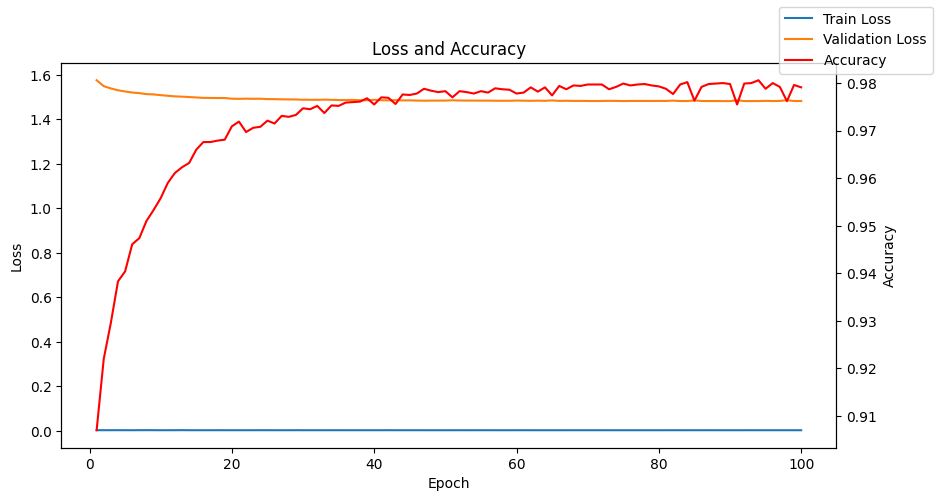

In [7]:
# Train model and save check point at different stages, then compute influence scores at each stage
model = DigitNet()
model, checkpoints, train_losses, accuracies, validation_losses = train_func_classification(model, nn.CrossEntropyLoss(), torch.optim.Adam(model.parameters(), lr=0.0001), mnist_train_loader, 
                                                  mnist_test_loader, 100, record_checkpoints=[3, 5, 7, 10, 15, 20, 40, 60, 80, 100])

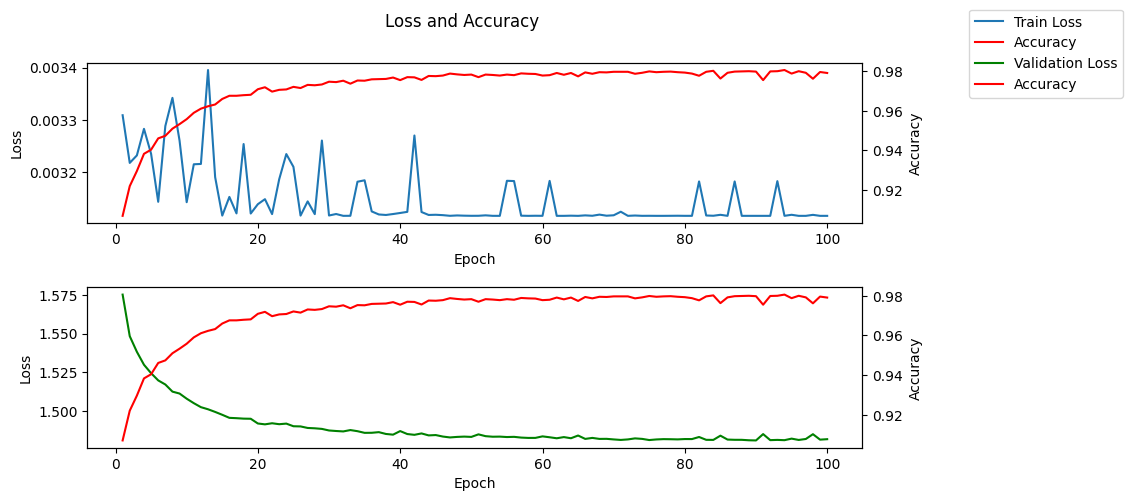

In [21]:
x_vals = np.arange(1, 101)
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(211)
ax1.plot(x_vals, train_losses, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(x_vals, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

ax3 = fig.add_subplot(212)
ax3.plot(x_vals, validation_losses, label='Validation Loss', color='g')
ax4 = ax3.twinx()
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Loss')
ax4.plot(x_vals, accuracies, label='Accuracy', color='r')
ax4.set_ylabel('Accuracy')

fig.suptitle('Loss and Accuracy')
fig.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.subplots_adjust(hspace=0.4)
plt.show()

In [15]:
checkpoints = ['../checkpoint/DigitNet/DigitNet_epoch_3_0.03.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_5_0.05.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_7_0.07.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_10_0.1.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_15_0.15.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_20_0.2.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_40_0.4.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_60_0.6.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_80_0.8.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_100_1.0.pth']
checkpoint_labels = np.array([3, 5, 7, 10, 15, 20, 40, 60, 80, 100])
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

In [22]:
checkpoints = ['../checkpoint/DigitNet/DigitNet_epoch_3_0.03.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_5_0.05.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_7_0.07.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_10_0.1.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_15_0.15.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_20_0.2.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_40_0.4.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_60_0.6.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_80_0.8.pth',
 '../checkpoint/DigitNet/DigitNet_epoch_100_1.0.pth']
checkpoint_labels = np.array([3, 5, 7, 10, 15, 20, 40, 60, 80, 100])
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
mnist_influences = influence_at_checkpoints(mnist_train_loader, mnist_test_loader, model, optimizer,
                                           nn.CrossEntropyLoss(), checkpoints, "cpu", appro="lissa")

Calculating influence scores:   0%|          | 0/10 [00:00<?, ?it/s]

Checkpoint loaded at epoch 3 with completion rate 0.03
completion_rate: 0.03
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores:  10%|█         | 1/10 [03:10<28:35, 190.59s/it]

Checkpoint loaded at epoch 5 with completion rate 0.05
completion_rate: 0.05
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores:  20%|██        | 2/10 [06:24<25:38, 192.28s/it]

...

Calculating influence scores:  80%|████████  | 8/10 [25:52<06:29, 194.87s/it]

Checkpoint loaded at epoch 80 with completion rate 0.8
completion_rate: 0.8
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores:  90%|█████████ | 9/10 [29:08<03:15, 195.27s/it]

Checkpoint loaded at epoch 100 with completion rate 1.0
completion_rate: 1.0
Start calculating influence scores...
LissaInfluenceModule
train data size: 60000
test data size: 10000
Calculating stest...


Calculating influence scores: 100%|██████████| 10/10 [32:27<00:00, 194.72s/it]


In [ ]:
torch.tensor(mnist_influences).shape
torch.save(mnist_influences, "../influences/mnist/mnist_influences.pt")
torch.save(accuracies, "../influences/mnist/mnist_accuracies.pt")
torch.save(validation_losses, "../influences/mnist/mnist_validation_losses.pt")
torch.save(train_losses, "../influences/mnist/mnist_train_losses.pt")

In [9]:
mnist_influences = torch.load("../influences/mnist/mnist_influences.pt")
accuracies = torch.load("../influences/mnist/mnist_accuracies.pt")
validation_losses = torch.load("../influences/mnist/mnist_validation_losses.pt")
train_losses = torch.load("../influences/mnist/mnist_train_losses.pt")

In [26]:
def top_or_least_influences(ckpt_influences, train_dataset, num_per_row=10, descending=True):
    ckpt_num = len(ckpt_influences)
    # fig, ax = plt.subplots(ckpt_num, num_per_row, figsize=(20, 20))
    ckpt_imgs = []
    for ckpt, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [train_dataset[index] for index in top_indexes]
        ckpt_imgs.append(top_influential_train_data)
    return ckpt_imgs
    
mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=20)
num_data = len(mnist_train)
x_vals =  list(range(1, 101))

In [16]:
# Validate Influence Function
def random_idx(checkpoint_influences, dataset, num_data, p):
    checkpoints_indices = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        indices = list(np.arange(len(dataset)))
        random_indices = random.sample(indices, num_select)
        checkpoints_indices.append(random_indices)
    return checkpoints_indices

p = 0.05
num_data = len(mnist_train)
random_indices = random_idx(mnist_influences, mnist_train, num_data, 1 - p)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def validate_influence(influences, train_dataset, test_dataloader, model_class, criterion, device, checkpoints, checkpoint_labels, p):
    # top_ckpts_embeds = top_last_influences(influences, train_dataset, int(p*num_data))
    validate_accuracies = []
    validate_train_losses = []
    validate_validation_losses = []
    rand_validate_accuracies = []
    rand_validate_train_losses = []
    rand_validate_validation_losses = []
    
    for i in tqdm(range(len(checkpoints)), desc=f"Validating influences"):
        sorted_influences = torch.argsort(torch.from_numpy(influences[i]), descending=True)
        top_indexes = sorted_influences[:int(p*num_data)]
        filtered_indices = [i for i in list(range(len(train_dataset))) if i not in top_indexes]
        residual_train_dataset = Subset(train_dataset, filtered_indices)
        residual_dataloader = DataLoader(residual_train_dataset, batch_size=20, shuffle=True)
        
        random_dataset = Subset(train_dataset, random_indices[i])
        random_dataloader = DataLoader(random_dataset, batch_size=64, shuffle=True)
        
        optimizer = torch.optim.Adam(model_class().parameters(), lr=0.0001)
        epochs = checkpoint_labels[i]
        model = model_class().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
        _, _, val_train_losses, val_accuracies, val_validation_losses = train_func_classification(
            model, criterion, optimizer, residual_dataloader, test_dataloader, epochs, save=False)
        model = model_class().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
        _, _, rand_train_losses, rand_accuracies, rand_validation_losses = train_func_classification(
            model, criterion, optimizer, random_dataloader, test_dataloader, epochs, save=False)
        
        validate_train_losses.append(val_train_losses)
        validate_accuracies.append(val_accuracies)
        validate_validation_losses.append(val_validation_losses)
        rand_validate_validation_losses.append(rand_validation_losses)
        rand_validate_accuracies.append(rand_accuracies)
        rand_validate_train_losses.append(rand_train_losses)
    return validate_train_losses, validate_accuracies, validate_validation_losses, rand_validate_train_losses, rand_validate_accuracies, rand_validate_validation_losses

validate_train_losses, validate_accuracies, validate_validation_losses, rand_validate_train_losses, rand_validate_accuracies, rand_validate_validation_losses = validate_influence(mnist_influences, mnist_train, mnist_test_loader, DigitNet, nn.CrossEntropyLoss(), device, checkpoints, checkpoint_labels, p)

Validating influences: 100%|██████████| 10/10 [4:38:28<00:00, 1670.83s/it]


In [18]:
torch.save(validate_train_losses, "../influences/mnist/mnist_validate_train_losses.pt")
torch.save(validate_accuracies, "../influences/mnist/mnist_validate_accuracies.pt")
torch.save(validate_validation_losses, "../influences/mnist/mnist_validate_validation_losses.pt")
torch.save(rand_validate_train_losses, "../influences/mnist/mnist_rand_validate_train_losses.pt")
torch.save(rand_validate_accuracies, "../influences/mnist/mnist_rand_validate_accuracies.pt")
torch.save(rand_validate_validation_losses, "../influences/mnist/mnist_rand_validate_validation_losses.pt")

In [19]:
validate_train_losses = torch.load("../influences/mnist/mnist_validate_train_losses.pt")
validate_accuracies = torch.load("../influences/mnist/mnist_validate_accuracies.pt")
validate_validation_losses = torch.load("../influences/mnist/mnist_validate_validation_losses.pt")
rand_validate_accuracies = torch.load("../influences/mnist/mnist_rand_validate_accuracies.pt")
rand_validate_train_losses = torch.load("../influences/mnist/mnist_rand_validate_train_losses.pt")
rand_validate_validation_losses = torch.load("../influences/mnist/mnist_rand_validate_validation_losses.pt")

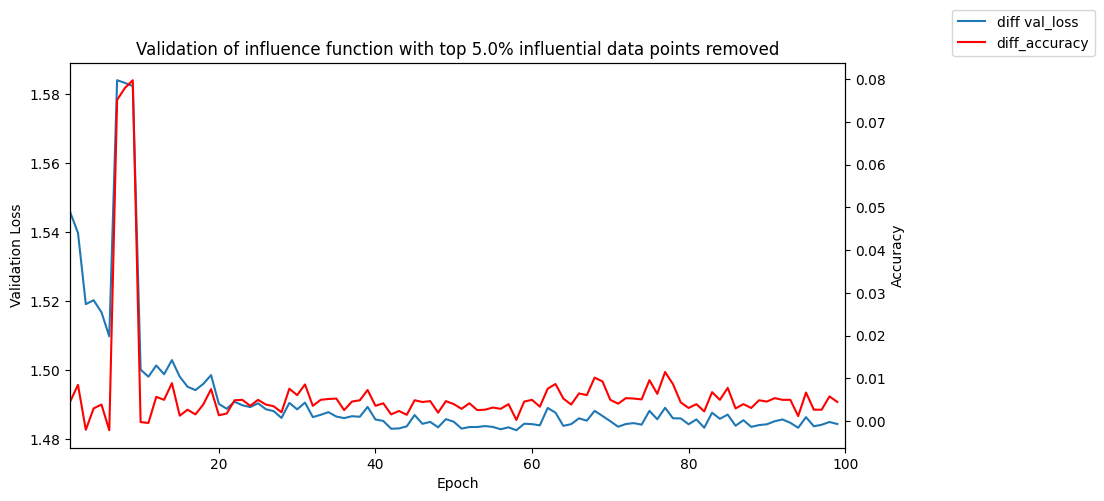

In [20]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_validation_losses, checkpoint_labels) - concat_ckpt_metrics(rand_validate_train_losses, checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_validate_accuracies, checkpoint_labels) - concat_ckpt_metrics(validate_accuracies, checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {p*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

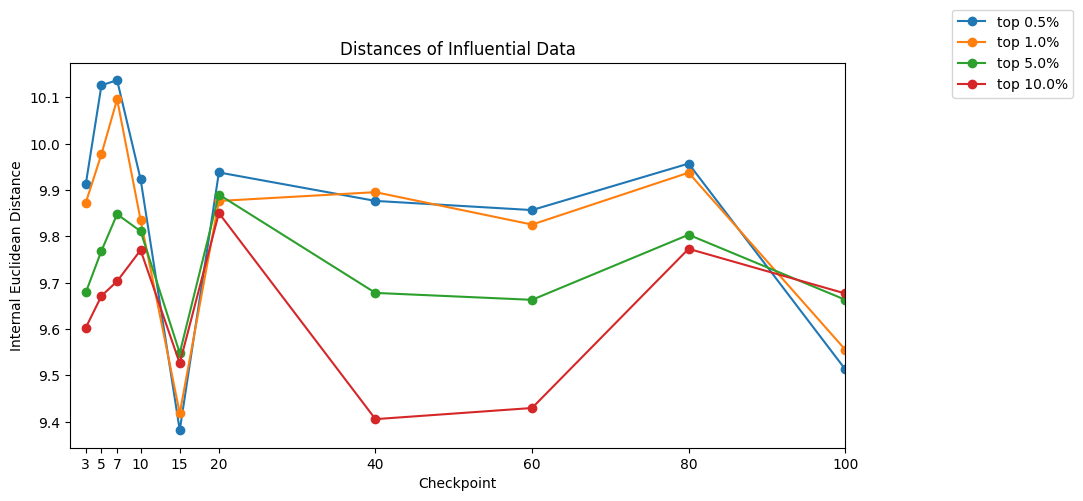

In [28]:
from sklearn.metrics.pairwise import euclidean_distances

def calc_inter_dist(imgs):
    distances = euclidean_distances(imgs, imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# Calculate distance of influential points towards other images
def calc_external_dist(inf_imgs, other_imgs):
    distances = euclidean_distances(inf_imgs, other_imgs)
    mean_distance = np.mean(distances)
    return mean_distance

# test selecting 0.5% 1% 5% 10% influential points
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances of Influential Data")
for p in [0.005, 0.01, 0.05, 0.1]:
    mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=int(p*num_data))
    inter_distances = []
    for ckpt, ckpt_imgs in enumerate(mnist_ckpt_imgs):
        ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
        # print(f"checkpoint: {ckpt}, shape:{ckpt_imgs.shape}")
        mean_dist = calc_inter_dist(ckpt_imgs)
        inter_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, inter_distances, 'o-', label=f"top {p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

learning speed stably decreases with increase checkpoint index
- when accuracy is rising, distances between most influential points is high;
- when accuracy is still, distance between most influential points are relatively lower;

In [37]:
import random
p = 0.01
# Select (1) random 1% training data; (2) last 1% influential data; (3) rest 99% data
def random_p_data(checkpoint_influences, train_dataset, num_data, p=0.01):
    checkpoints_data = []
    for _ in tqdm(checkpoint_influences):
        num_select = int(p * num_data)
        random_data = random.sample(list(train_dataset), num_select)
        checkpoints_data.append(random_data)
    return checkpoints_data

def rest_data(ckpt_influences, inf_num, train_dataset):
    ckpt_imgs = []
    for _, influences in enumerate(ckpt_influences):
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=True)
        rest_indexes = sorted_influences[inf_num:]
        top_influential_train_data = [train_dataset[index] for index in rest_indexes]
        imgs = []
        for i, (img, label) in enumerate(top_influential_train_data):
            imgs.append(np.array(img))        
        ckpt_imgs.append(imgs)
    return ckpt_imgs

100%|██████████| 10/10 [00:25<00:00,  2.50s/it]


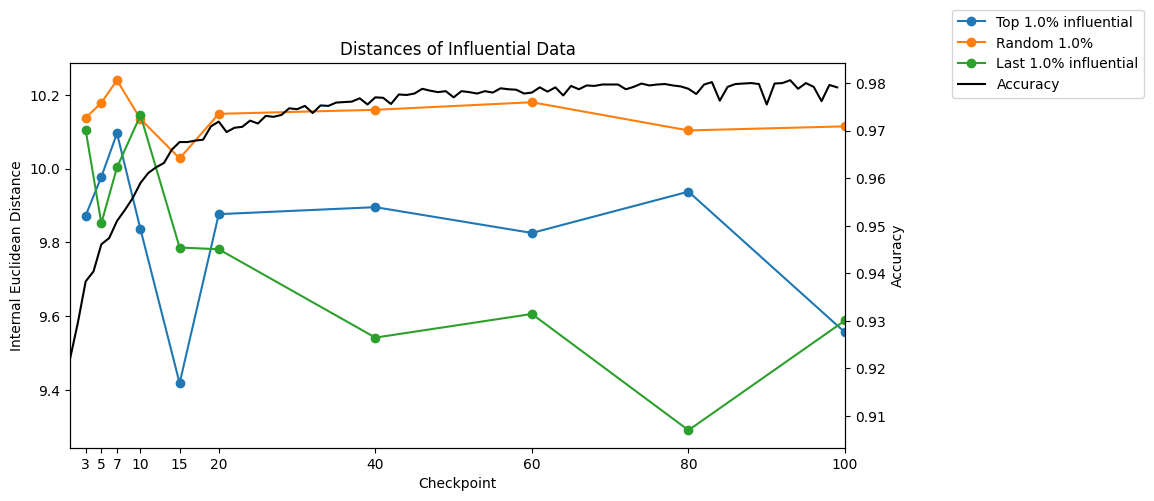

In [38]:
# select 0.5% influential points
num_data = len(mnist_train)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances of Influential Data")
mnist_ckpt_imgs = top_or_least_influences(mnist_influences, mnist_train, num_per_row=int(p*num_data))
top_inf_inter_distances = []
for ckpt_imgs in mnist_ckpt_imgs:
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    mean_dist = calc_inter_dist(ckpt_imgs)
    top_inf_inter_distances.append(mean_dist)
ax1.plot(checkpoint_labels, top_inf_inter_distances, 'o-', label=f"Top {p*100}% influential")

random_inter_distances = []
random_data = random_p_data(mnist_influences, mnist_train, len(mnist_train), p)
for data in random_data:
    ckpt_imgs = np.array([img[0] for img in data])
    mean_dist = calc_inter_dist(ckpt_imgs)
    random_inter_distances.append(mean_dist)
ax1.plot(checkpoint_labels, random_inter_distances, 'o-', label=f"Random {p*100}%")

# random_inter_distances = []
# random_data = random_p_data(mnist_influences, mnist_train, len(mnist_train), 0.01)
# for data in random_data:
#     ckpt_imgs = np.array([img[0] for img in data])
#     mean_dist = calc_inter_dist(ckpt_imgs)
#     random_inter_distances.append(mean_dist)
# ax1.plot(checkpoint_labels, random_inter_distances, 'o-', label="Random 1%")

last_inter_distances = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    mean_dist = calc_inter_dist(ckpt_imgs)
    last_inter_distances.append(mean_dist)
ax1.plot(checkpoint_labels, last_inter_distances, 'o-', label=f"Last {p*100}% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Checkpoint 0-5 (accuracy rapidly increasing), top influential points have greatest difference with least influential points;\
No clear trend of changing for random points in dataset.

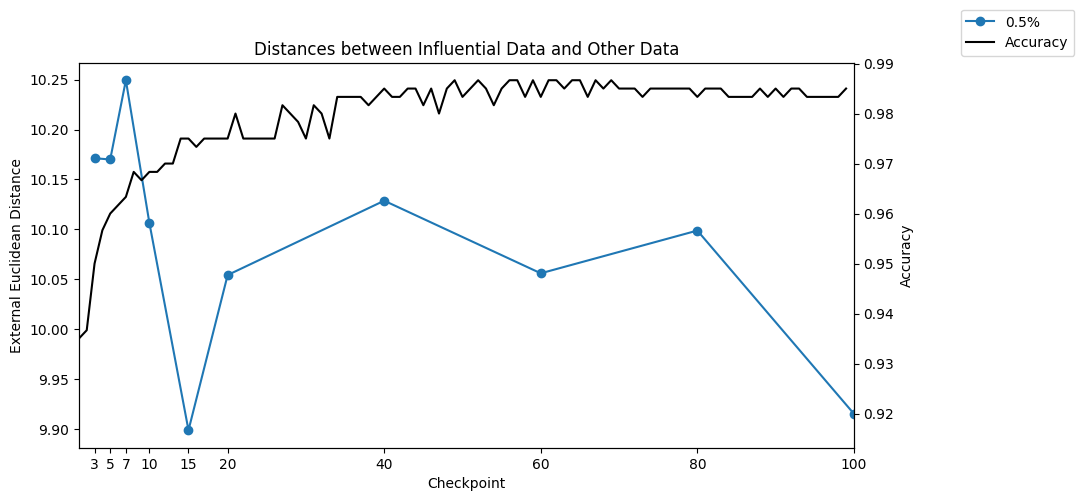

In [70]:
# Euclidean distance from influential points to other points
p = 0.005

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
plt.title("Distances between Influential Data and Other Data")
distances = []
for i in range(len(checkpoints)):
    inf_imgs = np.array([img[0] for img in mnist_ckpt_imgs[i]])
    rand_imgs = np.array([img[0] for img in random_data[i]])
    mean_dist = calc_external_dist(inf_imgs, rand_imgs)
    distances.append(mean_dist)
    
ax1.plot(checkpoint_labels, distances, 'o-', label=f"{p*100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("External Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

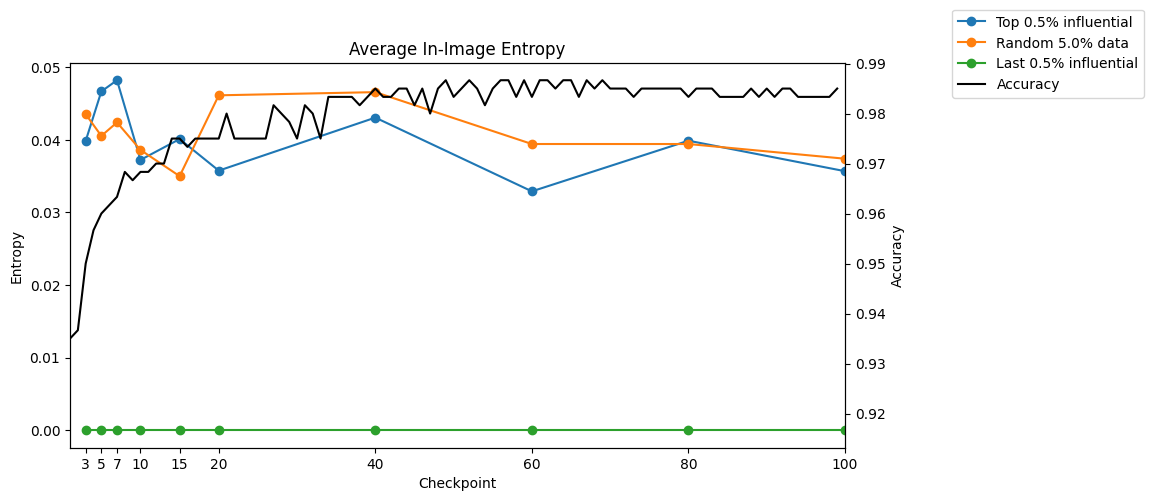

In [71]:
def calculate_entropy(image):
    hist, _ = np.histogram(image[0], bins=256, range=(0, 256))
    probabilities = hist / hist.sum()
    return -np.sum(probabilities * np.log2(probabilities + 1e-20))

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

entropies = []
for imgs in mnist_ckpt_imgs:
    ckpt_entropies = [calculate_entropy(img) for img in imgs]
    mean_entropy = np.mean(ckpt_entropies)
    entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, entropies, 'o-', label=f"Top {p*100}% influential")

randimgs_entropies = []
for data in random_data:
    ckpt_entropies = [calculate_entropy(img) for img in data]
    mean_entropy = np.mean(ckpt_entropies)
    randimgs_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, randimgs_entropies, 'o-', label=f"Random {p*10*100}% data")


last_inf_entropies = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    last_inf_entropy = [calculate_entropy(img[0]) for img in ckpt_imgs]
    mean_entropy = np.mean(last_inf_entropy)
    last_inf_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, last_inf_entropies, 'o-', label="Last 0.5% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Entropy")
ax1.set_xticks(checkpoint_labels)
plt.title("Average In-Image Entropy")
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

entropy at rapid learning stage is high; gradually reduce at later stage
**with a little rise at the last learning stage that accuracy rises slightly**

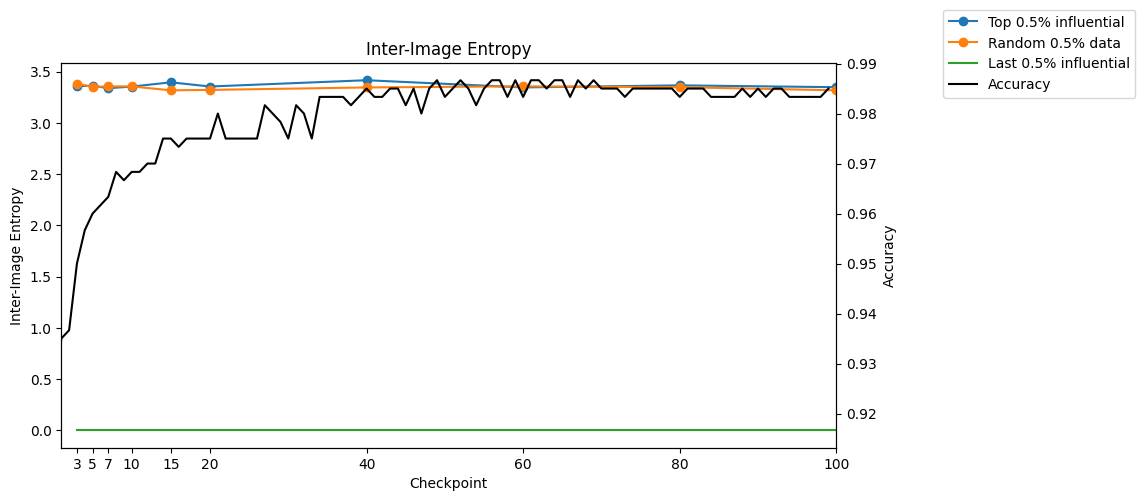

In [72]:
from scipy.spatial.distance import pdist
from scipy.stats import entropy

def image_pairwise_entropy(features):
    pairwise_distances = pdist(features, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=50, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    return entropy(distance_probs)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

top_inf_pw_entropies = []
for imgs in mnist_ckpt_imgs:
    imgs = np.array([img[0] for img in imgs])
    ckpt_entropies = image_pairwise_entropy(imgs)
    top_inf_pw_entropies.append(ckpt_entropies)
ax1.plot(checkpoint_labels, top_inf_pw_entropies, 'o-', label=f"Top {p*100}% influential")

randimgs_pw_entropies = []
for data in random_data:
    imgs = np.array([img[0] for img in data])
    ckpt_entropies = image_pairwise_entropy(imgs)
    randimgs_pw_entropies.append(ckpt_entropies)
ax1.plot(checkpoint_labels, randimgs_pw_entropies, 'o-', label=f"Random {p*100}% data")


last_inf_pw_entropies = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    last_inf_entropy = [img[0] for img in ckpt_imgs]
    ckpt_entropies = image_pairwise_entropy(last_inf_entropy)
    last_inf_pw_entropies.append(mean_entropy)
ax1.plot(checkpoint_labels, last_inf_pw_entropies, label="Last 0.5% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Inter-Image Entropy")
plt.title("Inter-Image Entropy")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

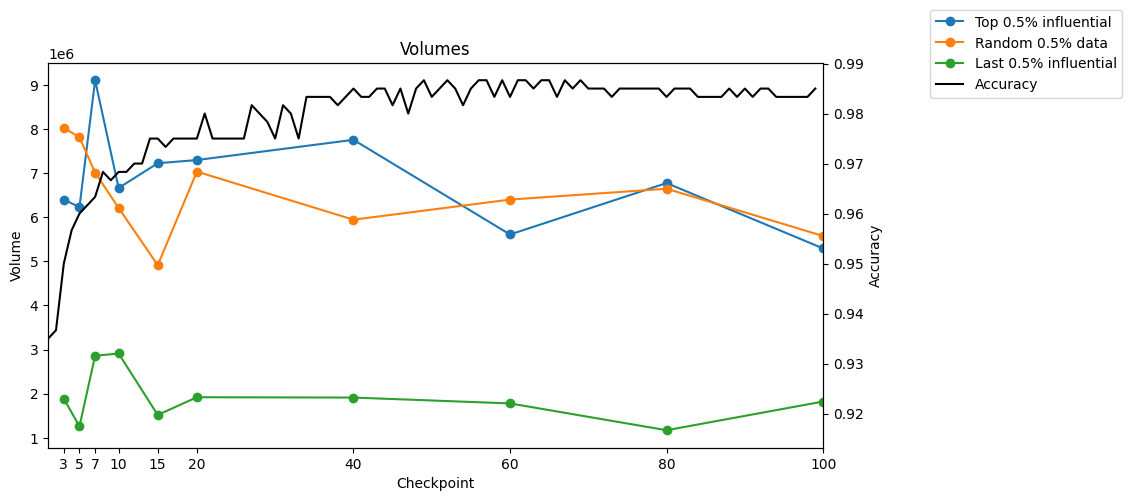

In [73]:
from sklearn.decomposition import PCA

def volume(images):
    return np.sqrt(np.linalg.det(images.T@images))

def pca(x, components):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=components)
    pca.fit(x_std)
    return pca.components_

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

top_inf_volumes = []
for ckpt_imgs in mnist_ckpt_imgs:
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    W = pca(ckpt_imgs, 4)
    Z_imgs = ckpt_imgs @ W.T
    # print(f"Z_imgs: {Z_imgs.shape}, volume: {volume(Z_imgs)}")
    # print(f"checkpoint: {ckpt_imgs.shape}")
    top_inf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, top_inf_volumes, 'o-', label=f"Top {p*100}% influential")

randimgs_volumes = []
for data in random_data:
    ckpt_imgs = np.array([img[0] for img in data])
    W = pca(ckpt_imgs, 4)
    Z_imgs = ckpt_imgs @W.T
    randimgs_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, randimgs_volumes, 'o-', label=f"Random {p*100}% data")


last_inf_volumes = []
for ckpt_imgs in top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False):
    ckpt_imgs = np.array([img[0] for img in ckpt_imgs])
    W = pca(ckpt_imgs, 4)
    Z_imgs = ckpt_imgs @W.T
    last_inf_volumes.append(volume(Z_imgs))
ax1.plot(checkpoint_labels, last_inf_volumes, 'o-', label=f"Last {p*100}% influential")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Volume")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Volumes")
plt.show()

Volume of most influential points siginificantly reflect accuracy changing during training process.

Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 7 with completion rate 0.07
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 7 with completion rate 0.07
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpo

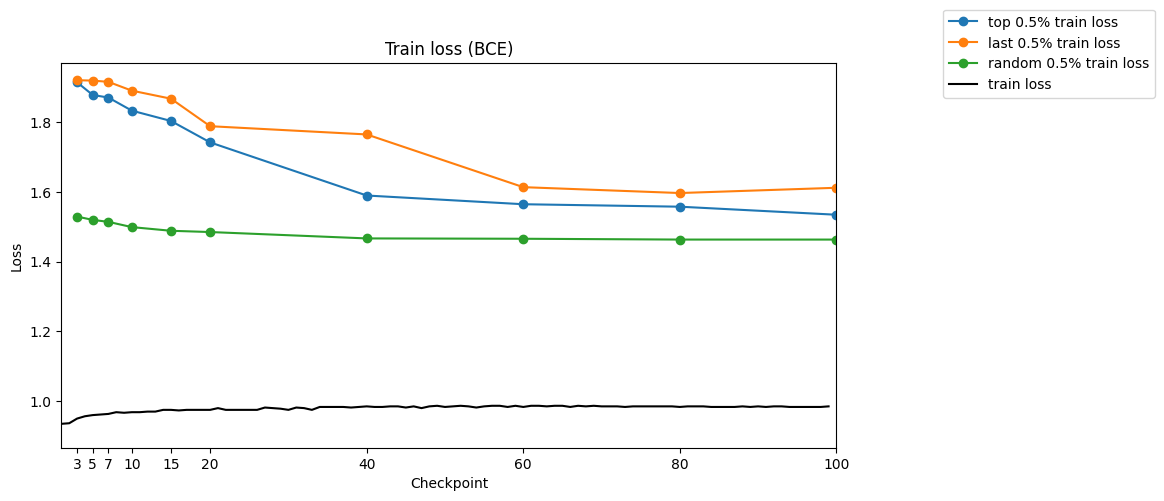

In [74]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
labels = ["top", "last", "random"]
last_ckpts_embeds = top_or_least_influences(mnist_influences, mnist_train, int(p*num_data), descending=False)
for j, ckpts_embeds in enumerate([mnist_ckpt_imgs, last_ckpts_embeds, random_data]):
    train_losses = [] # BCE loss
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints[i]
        inputs = torch.tensor(np.array([embed[0] for embed in embeds]))
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        optimizer = torch.optim.Adam(DigitNet().parameters(), lr=0.0001)
        model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
        loss_fn = nn.CrossEntropyLoss()
        outputs = model(inputs)
        loss = loss_fn(outputs, expect_val)
        train_losses.append(loss.item())
    ax1.plot(checkpoint_labels, train_losses, 'o-', 
             label=f"{labels[j]} {p*100}% train loss")

plt.title("Train loss (BCE)")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Loss")
ax1.set_xticks(checkpoint_labels)
train_losses = torch.load("../influences/dogfish/dogfish_train_losses.pt")
ax1.plot(accuracies, label="train loss", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 7 with completion rate 0.07
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpoint loaded at epoch 80 with completion rate 0.8
Checkpoint loaded at epoch 100 with completion rate 1.0
Checkpoint loaded at epoch 3 with completion rate 0.03
Checkpoint loaded at epoch 5 with completion rate 0.05
Checkpoint loaded at epoch 7 with completion rate 0.07
Checkpoint loaded at epoch 10 with completion rate 0.1
Checkpoint loaded at epoch 15 with completion rate 0.15
Checkpoint loaded at epoch 20 with completion rate 0.2
Checkpoint loaded at epoch 40 with completion rate 0.4
Checkpoint loaded at epoch 60 with completion rate 0.6
Checkpo

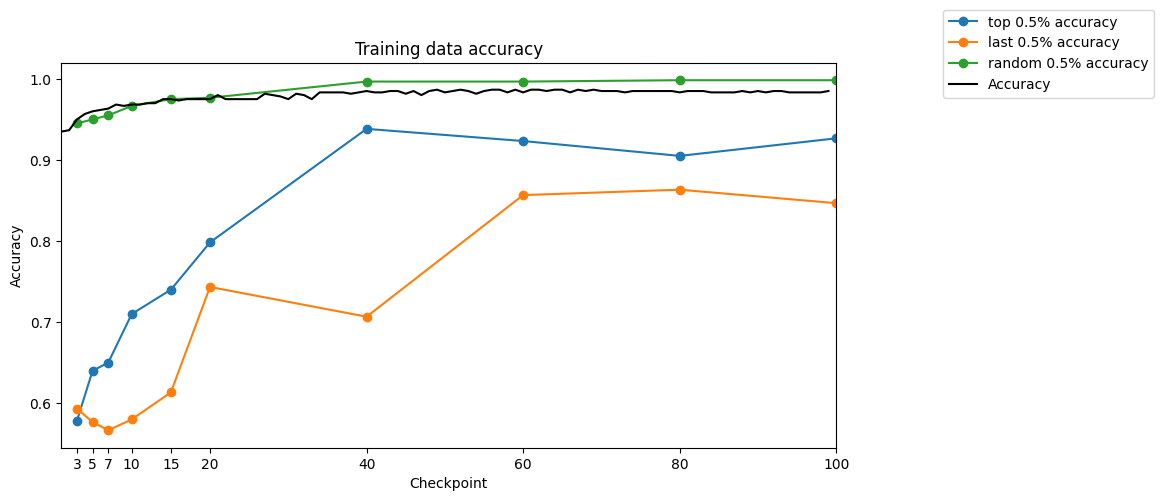

In [75]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([mnist_ckpt_imgs, last_ckpts_embeds, random_data]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints[i]
        inputs = torch.tensor(np.array([embed[0] for embed in embeds]), dtype=torch.float32, device=device)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        model, optimizer, _, _ = load_checkpoint(DigitNet().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=-1)
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy)
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/dogfish/dogfish_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()